In [12]:
# notebooks/01_eda_market.ipynb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configuración de gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# Cargar datos procesados
# Usamos rutas relativas para que funcione en cualquier PC
PROJECT_DIR = Path("..").resolve()
TRAIN_PATH = PROJECT_DIR / "data" / "processed" / "train.csv"

print(f"📂 Cargando datos desde: {TRAIN_PATH}")

df = pd.read_csv(TRAIN_PATH)

print(f"✅ Datos cargados: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()

📂 Cargando datos desde: /home/medra/tfg-market-intelligence/data/processed/train.csv
✅ Datos cargados: 1540 filas, 7 columnas


,job_id,title,description,max_salary,pay_period,formatted_work_type,skills
0,3891819692,Data Engineer (LEAD),"Please Note: As of July 22, 2021, our team will require that all candidate submissions include a LinkedIn profile. Please do not submit any candid...",NaN,NaN,Full-time,['Information Technology']
1,3886481756,JP Morgan Chase Institute - Data Science Research Associate,This inclusive employer is a member of myGwork – the largest global platform for the LGBTQ+ business community. \n\nJoin the team that conducts i...,NaN,NaN,Full-time,['Other']
2,3902331067,Manager Data Science,"Discover. A brighter future.\n\nWith us, you’ll do meaningful work from Day 1. Our collaborative culture is built on three core behaviors: We Play...",177300.0,YEARLY,Full-time,"['Engineering', 'Information Technology']"
3,3900943383,AI Business Development Manager,Why Work at Lenovo\n\nWe are Lenovo. We do what we say. We own what we do. We WOW our customers.\n\nLenovo is a US$62 billion revenue global techn...,168000.0,YEARLY,Full-time,"['Business Development', 'Sales']"
4,3905826251,Senior Data Scientist,"When you join Verizon\n\nVerizon is one of the world's leading providers of technology and communications services, transforming the way we connec...",NaN,NaN,Full-time,['Other']


In [13]:
# Celda 2: Análisis de Nulos
print("📊 Porcentaje de datos faltantes:")
missing = df.isnull().mean() * 100
print(missing[missing > 0])

print("\n💰 Total ofertas con salario:", df['max_salary'].notna().sum())

📊 Porcentaje de datos faltantes:
max_salary    69.025974
pay_period    66.883117
skills         2.207792
dtype: float64

💰 Total ofertas con salario: 477


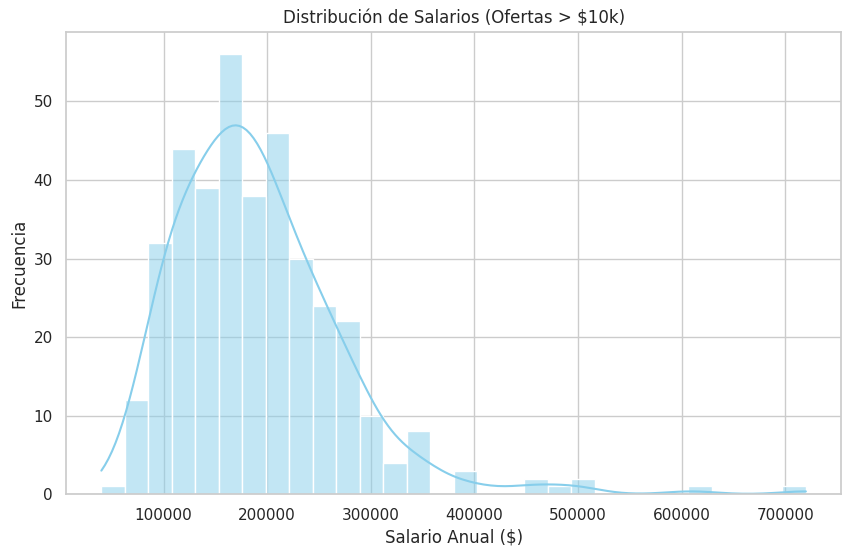

In [14]:
# Celda 3: Distribución de Salarios Anuales
plt.figure(figsize=(10, 6))

# Filtramos solo los que tienen salario y asumimos que son anuales (mayoría > 10k)
# OJO: Esto es una simplificación para el EDA inicial
salary_data = df[df['max_salary'] > 10000] 

sns.histplot(salary_data['max_salary'], bins=30, kde=True, color='skyblue')
plt.title('Distribución de Salarios (Ofertas > $10k)')
plt.xlabel('Salario Anual ($)')
plt.ylabel('Frecuencia')
plt.show()

/tmp/ipykernel_21273/2236823298.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=[x[1] for x in skill_counts], y=[x[0] for x in skill_counts], palette='viridis')


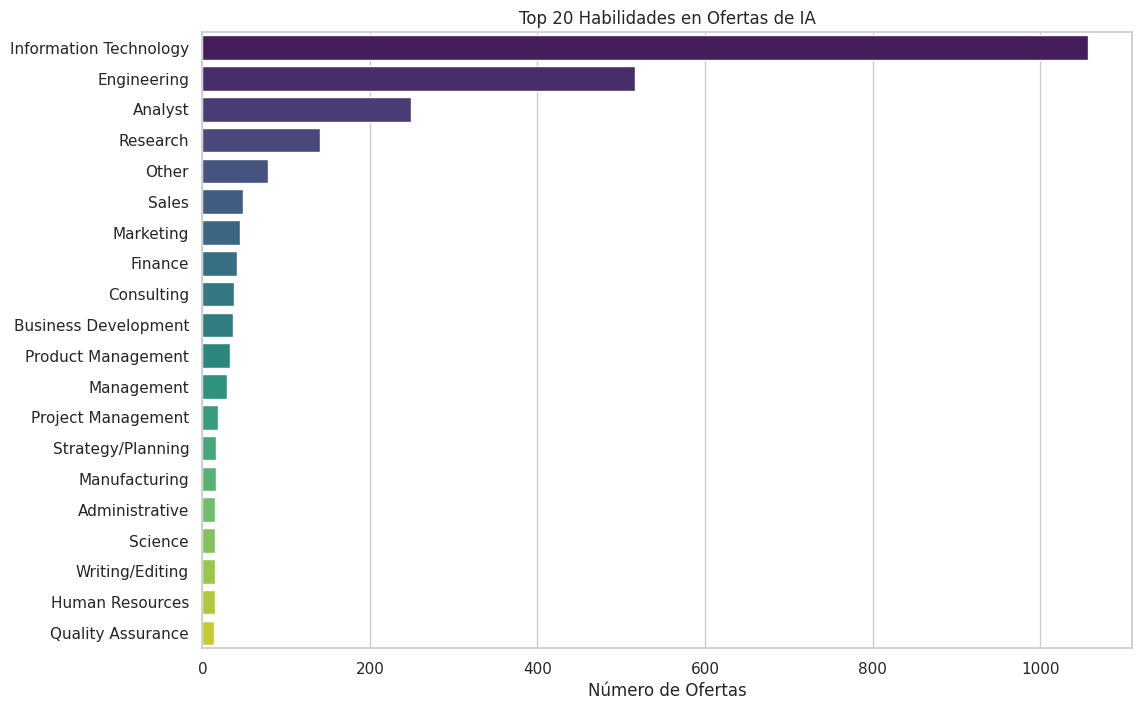

In [15]:
# Celda 4: Top 20 Habilidades más demandadas
import ast
from collections import Counter

# 1. Convertir string "['A', 'B']" a lista real ['A', 'B']
# Usamos dropna() porque si hay nulos, ast.literal_eval falla
clean_skills = df['skills'].dropna().apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else [])

# 2. Aplanar la lista (de lista de listas a una lista gigante de skills)
all_skills = [skill for sublist in clean_skills for skill in sublist]

# 3. Contar
skill_counts = Counter(all_skills).most_common(20)

# 4. Graficar
plt.figure(figsize=(12, 8))
sns.barplot(x=[x[1] for x in skill_counts], y=[x[0] for x in skill_counts], palette='viridis')
plt.title('Top 20 Habilidades en Ofertas de IA')
plt.xlabel('Número de Ofertas')
plt.show()

In [16]:
# Celda 5: Detective de Datos (Versión Blindada)
pd.set_option('display.max_colwidth', 150)

bad_skills = ['Sales', 'Management', 'Customer Service']

def has_bad_skill(skill_list_str):
    # Si no es texto (es decir, es NaN/float), asumimos que no es sospechoso
    if not isinstance(skill_list_str, str):
        return False
    return any(bad in skill_list_str for bad in bad_skills)

# Filtramos
suspicious_jobs = df[df['skills'].apply(has_bad_skill)]

print(f"🕵️ Ofertas sospechosas: {len(suspicious_jobs)}")
print("Ejemplos de títulos sospechosos:")
print(suspicious_jobs[['title', 'skills']].head(10))

🕵️ Ofertas sospechosas: 131
Ejemplos de títulos sospechosos:
                                                                        title  \
3                                             AI Business Development Manager   
25   Part-Time Administrative Assistant to Exciting AI Music Focused Start-Up   
31                                            Sr Analyst, Marketing Analytics   
36                                     Power BI Data Engineer, Semantic Layer   
45                                       Senior Strategic Partner Manager, AI   
50                                            Sr. Product Manager - Analytics   
59                    Director of Portfolio Analytics - CAT Modeling (#54997)   
81                         IT Project Manager, Enterprise Analytics (87454BR)   
100                  Director of Portfolio Analytics (Full Stack Development)   
112        Hybrid - Paid Search Analyst (Up to $125K, Google Analytics Cert.)   

                                               